# Length of Hospital Stay Prediction Pipeline
## Jett Guitteau
### This project is a self-guided part of a learning experience at Qualees to explore machine learning methods and compare a local python machine learning pipeline with their TweenMe platform which can augment data to enhance model performance. This project focuses on regression. 

This project utilizes a dataset that includes around 100,000 records of hospital stays for patients with diabetes. 

The features of the dataset include patient race, gender, age, their admission type, discharge disposition, key diabetes lab values, diagnoses codes, and medication information. The goal of this model is to predict length of stay at admission, so columns that reflect information gathered during the stay or at discharge are removed to avoid data leakage. 

The dataset can be found on the UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

In [34]:
diabetes = pd.read_csv("diabetic_data.csv")
diabetes.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


First, the columns reflecting information gathered during or after the visit are to be dropped.

In [35]:
meds = diabetes.loc[:, "metformin":"metformin-pioglitazone"].columns.tolist()
print(len(meds), meds)

during_or_after = [
    "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
    "max_glu_serum", "A1Cresult", "discharge_disposition_id", "readmitted",
    "change", "diabetesMed", "diag_2", "diag_3"
] + meds

diabetes = diabetes.drop(columns=during_or_after)

23 ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


Since diag_1 is the coded primary diagnosis, it will be used as a proxy for the admitting diagnosis, so it will be kept while the secondary diagnoses are dropped. The ICD codes will be simplified to their main categories, removing the smaller details given by the numbers after the decimal 
(ex. 300.01 and 300.03 will merge to 300).

In [36]:
diabetes["diag_1"] = diabetes["diag_1"].str[:3]

In [37]:
'''Convert nominal admission columns to strings to match data types with the rest of the categorical data. 
No need to map the exact names from the IDS as we are only interested in treating them as categorical variables. 
They will be one-hot encoded later in the pipeline. However, the various values that reflect a null value will be changed to NaN.'''

nominal_cols = ['admission_type_id', 'admission_source_id']
diabetes[nominal_cols] = diabetes[nominal_cols].astype('str') 
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   encounter_id         101766 non-null  int64
 1   patient_nbr          101766 non-null  int64
 2   race                 101766 non-null  str  
 3   gender               101766 non-null  str  
 4   age                  101766 non-null  str  
 5   weight               101766 non-null  str  
 6   admission_type_id    101766 non-null  str  
 7   admission_source_id  101766 non-null  str  
 8   time_in_hospital     101766 non-null  int64
 9   payer_code           101766 non-null  str  
 10  medical_specialty    101766 non-null  str  
 11  number_outpatient    101766 non-null  int64
 12  number_emergency     101766 non-null  int64
 13  number_inpatient     101766 non-null  int64
 14  diag_1               101766 non-null  str  
dtypes: int64(6), str(9)
memory usage: 11.6 MB


In [38]:
'''Treat various values that reflect a null value as NaN. For example, admission_type_id has 8 codes, 
with 5 meaning Not Available, 6 meaning NULL, and 8 meaning Not Mapped. All of these mean missing or unavailable values and 
should be treated as NaN. Similarly, admission_source_id has codes that reflect missing or unavailable values, which should 
also be treated as NaN.'''

diabetes["admission_type_id"] = diabetes["admission_type_id"].replace({"5": np.nan, "6": np.nan, "8": np.nan})
diabetes["admission_source_id"] = diabetes["admission_source_id"].replace({"9": np.nan, "15": np.nan, "17": np.nan, "20": np.nan, "21": np.nan})

In [39]:
diabetes["admission_type_id"].value_counts(dropna=False)

admission_type_id
1      53990
3      18869
2      18480
NaN    10396
7         21
4         10
Name: count, dtype: int64

In [40]:
diabetes["admission_source_id"].value_counts(dropna=False)

admission_source_id
7      57494
1      29565
NaN     7067
4       3187
6       2264
2       1104
5        855
3        187
8         16
22        12
10         8
14         2
11         2
25         2
13         1
Name: count, dtype: int64

In [41]:
for column in diabetes.columns:
    diabetes[column] = diabetes[column].replace("?", np.nan)
for column in diabetes.columns:
    if (diabetes[column].isna().sum() / diabetes.shape[0] * 100).round(2) > 0:
        print(f'Column "{column}" has missing values. Percentage of missing values:')
        print((diabetes[column].isna().sum() / diabetes.shape[0] * 100).round(2))

Column "race" has missing values. Percentage of missing values:
2.23
Column "weight" has missing values. Percentage of missing values:
96.86
Column "admission_type_id" has missing values. Percentage of missing values:
10.22
Column "admission_source_id" has missing values. Percentage of missing values:
6.94
Column "payer_code" has missing values. Percentage of missing values:
39.56
Column "medical_specialty" has missing values. Percentage of missing values:
49.08
Column "diag_1" has missing values. Percentage of missing values:
0.02


In [42]:
diabetes = diabetes.drop(columns="weight")
diabetes.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,number_outpatient,number_emergency,number_inpatient,diag_1
0,2278392,8222157,Caucasian,Female,[0-10),NaN,1,1,NaN,Pediatrics-Endocrinology,0,0,0,250
1,149190,55629189,Caucasian,Female,[10-20),1,7,3,NaN,NaN,0,0,0,276
2,64410,86047875,AfricanAmerican,Female,[20-30),1,7,2,NaN,NaN,2,0,1,648
3,500364,82442376,Caucasian,Male,[30-40),1,7,2,NaN,NaN,0,0,0,8
4,16680,42519267,Caucasian,Male,[40-50),1,7,1,NaN,NaN,0,0,0,197


In [43]:
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   encounter_id         101766 non-null  int64
 1   patient_nbr          101766 non-null  int64
 2   race                 99493 non-null   str  
 3   gender               101766 non-null  str  
 4   age                  101766 non-null  str  
 5   admission_type_id    91370 non-null   str  
 6   admission_source_id  94699 non-null   str  
 7   time_in_hospital     101766 non-null  int64
 8   payer_code           61510 non-null   str  
 9   medical_specialty    51817 non-null   str  
 10  number_outpatient    101766 non-null  int64
 11  number_emergency     101766 non-null  int64
 12  number_inpatient     101766 non-null  int64
 13  diag_1               101745 non-null  str  
dtypes: int64(6), str(8)
memory usage: 10.9 MB


Next we will check for and remove all duplicate encounters, as each should be unique. 

In [44]:
diabetes["encounter_id"].duplicated().sum()

np.int64(0)

The encounter_id is already unique, therefore the column can be dropped as it won't be used for the model. Next we will check for duplicate patients, which would be fine to have since the encounter_id uniqueness indicates that these would be separate hospital stays for the patients seen more than once. 

In [45]:
diabetes["patient_nbr"].duplicated().sum()

np.int64(30248)

A group-aware split could be considered to maintain these rows, but for simplicity the duplicates will be removed to keep only one record per patient, reflecting the first encounter for each. After this drop, there will still be over 70,000 records.

In [46]:
diabetes = diabetes.drop_duplicates(subset="patient_nbr")
diabetes.shape

(71518, 14)

In [47]:
# Dropping the now unnecessary columns: "encounter_id" and "patient_nbr"
diabetes = diabetes.drop(columns=["encounter_id", "patient_nbr"])
diabetes.info()

<class 'pandas.DataFrame'>
Index: 71518 entries, 0 to 101765
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   race                 69570 non-null  str  
 1   gender               71518 non-null  str  
 2   age                  71518 non-null  str  
 3   admission_type_id    63465 non-null  str  
 4   admission_source_id  66319 non-null  str  
 5   time_in_hospital     71518 non-null  int64
 6   payer_code           40475 non-null  str  
 7   medical_specialty    37041 non-null  str  
 8   number_outpatient    71518 non-null  int64
 9   number_emergency     71518 non-null  int64
 10  number_inpatient     71518 non-null  int64
 11  diag_1               71507 non-null  str  
dtypes: int64(4), str(8)
memory usage: 7.1 MB


In [48]:
# Going back to the two columns with high missing value counts: "medical_specialty" and "payer_code"
diabetes["medical_specialty"].value_counts(dropna=False)

medical_specialty
NaN                       34477
InternalMedicine          10919
Family/GeneralPractice     5118
Emergency/Trauma           4465
Cardiology                 4266
                          ...  
SportsMedicine                1
Speech                        1
Perinatology                  1
Neurophysiology               1
Resident                      1
Name: count, Length: 71, dtype: int64

In [49]:
diabetes["payer_code"].value_counts(dropna=False)

payer_code
NaN    31043
MC     20414
HM      4022
BC      3432
SP      3347
MD      2197
CP      1986
UN      1879
CM      1334
OG       658
PO       463
DM       374
CH       117
WC       117
OT        65
SI        37
MP        32
FR         1
Name: count, dtype: int64

Both columns have substantial missingness. Because payer code and medical specialty are categorical, I will keep these encounters and represent missing values as an explicit `Missing` category instead of assigning the most common category or dropping either feature. This preserves the information that a value was unrecorded; that pattern may be predictive, though it may also reflect documentation practices rather than patient characteristics.

In [50]:
diabetes["medical_specialty"] = diabetes["medical_specialty"].fillna("Missing")
diabetes["payer_code"] = diabetes["payer_code"].fillna("Missing")

The same idea will be applied to remaining null values throughout the categorical features, with the exception of 11 missing values in diag_1. Those rows can just be removed as it represents a very small portion of the data. 

In [51]:
diabetes = diabetes.dropna(subset=["diag_1"])

cols = ["race", "admission_type_id", "admission_source_id"]
diabetes[cols] = diabetes[cols].fillna("Missing")

diabetes.info() # Verify all values have the same non-null count which matches the number of entries. 

<class 'pandas.DataFrame'>
Index: 71507 entries, 0 to 101765
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   race                 71507 non-null  str  
 1   gender               71507 non-null  str  
 2   age                  71507 non-null  str  
 3   admission_type_id    71507 non-null  str  
 4   admission_source_id  71507 non-null  str  
 5   time_in_hospital     71507 non-null  int64
 6   payer_code           71507 non-null  str  
 7   medical_specialty    71507 non-null  str  
 8   number_outpatient    71507 non-null  int64
 9   number_emergency     71507 non-null  int64
 10  number_inpatient     71507 non-null  int64
 11  diag_1               71507 non-null  str  
dtypes: int64(4), str(8)
memory usage: 7.1 MB


The data cleaning is now mostly completed, aside from grouping rare categories which will be done within the scikit-learn pipeline, after the train/test split. 

In [52]:
X = diabetes.drop(columns="time_in_hospital")
y = diabetes["time_in_hospital"]
print(X.columns.tolist())
print(X.dtypes)

['race', 'gender', 'age', 'admission_type_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1']
race                     str
gender                   str
age                      str
admission_type_id        str
admission_source_id      str
payer_code               str
medical_specialty        str
number_outpatient      int64
number_emergency       int64
number_inpatient       int64
diag_1                   str
dtype: object


A plot of the target will give a picture of the data we have and give insight as to what our statistics may reflect and should compare to. 

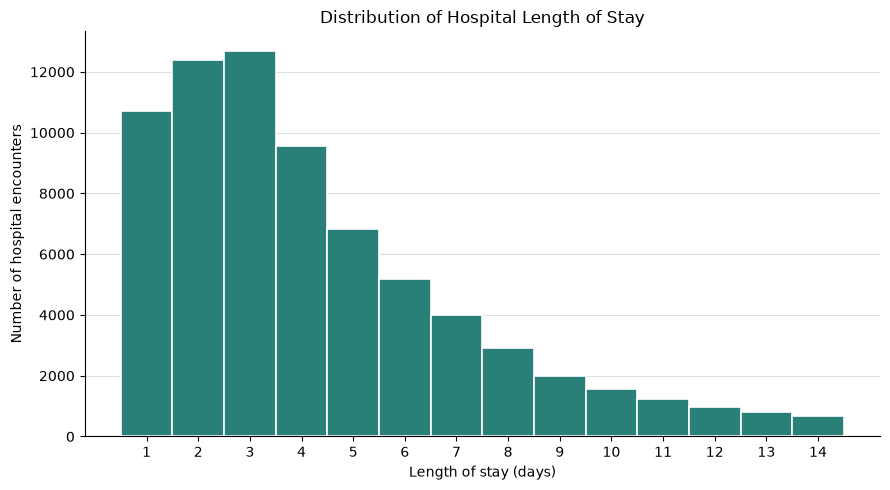

<Figure size 640x480 with 0 Axes>

In [53]:
max_day = int(y.max())
day_bins = np.arange(0.5, max_day + 1.5, 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    y,
    bins=day_bins,
    color="#2A7F78",
    edgecolor="white",
    linewidth=1.2,
)
ax.set(
    title="Distribution of Hospital Length of Stay",
    xlabel="Length of stay (days)",
    ylabel="Number of hospital encounters",
    xticks=np.arange(1, max_day + 1),
)
ax.grid(axis="y", color="#D9E2E1", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
plt.clf()

In [54]:
y.describe()

count    71507.000000
mean         4.289174
std          2.949335
min          1.000000
25%          2.000000
50%          3.000000
75%          6.000000
max         14.000000
Name: time_in_hospital, dtype: float64

Mean > median is expected given the right skew. The median of 3 is the naive guess. 
The max of 14 in the data will limit the model's capability to predict longer visits. 

** Potential later improvement: add more models than just random forest, but log adjust y to reduce skew for linear models. **

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(57205, 11)

 (14302, 11)


In [56]:
def report(name, model):
    for label, Xs, ys in [("train", X_train, y_train), ("test", X_test, y_test)]:
        p = model.predict(Xs)
        print(f"{name:9} {label:5} MAE={mean_absolute_error(ys, p):.2f}  "
              f"RMSE={root_mean_squared_error(ys, p):.2f}  R2={r2_score(ys, p):.3f}")

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
y_base = baseline.predict(X_test)
base_mae = mean_absolute_error(y_test, y_base)
base_rmse = root_mean_squared_error(y_test, y_base)
base_r2 = r2_score(y_test, y_base)
dummy_metrics = f"DummyRegressor Metrics: MAE = {base_mae:.3f} | RMSE = {base_rmse:.3f} | R2 = {base_r2:.3f}"
print(dummy_metrics)

DummyRegressor Metrics: MAE = 2.207 | RMSE = 3.189 | R2 = -0.197


In [57]:
cat_cols = X_train.select_dtypes(include="str").columns
cat_cols.tolist() # Verification of categorical columns

['race',
 'gender',
 'age',
 'admission_type_id',
 'admission_source_id',
 'payer_code',
 'medical_specialty',
 'diag_1']

In [58]:
preprocess = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01), cat_cols)],
    remainder="passthrough"
)

In [59]:
model = Pipeline([
    ("prep", preprocess),
    ("rf", RandomForestRegressor(n_estimators=100, random_state=42)),
])

param_grid = {
    "rf__min_samples_leaf": [5, 20, 50, 100],
    "rf__max_features": [0.3, 0.6, 1.0],
}

search = GridSearchCV(model, param_grid, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)
search.fit(X_train, y_train)

print(search.best_params_, -search.best_score_)

{'rf__max_features': 0.6, 'rf__min_samples_leaf': 20} 2.168462894998447


In [60]:
res = pd.DataFrame(search.cv_results_)
res["MAE"] = -res["mean_test_score"]
cols = ["param_rf__min_samples_leaf", "param_rf__max_features", "MAE", "std_test_score"]
res[cols].sort_values("MAE")

,param_rf__min_samples_leaf,param_rf__max_features,MAE,std_test_score
5,20,0.6,2.168463,0.013555
1,20,0.3,2.168800,0.014242
9,20,1.0,2.169812,0.014217
10,50,1.0,2.171368,0.014382
6,50,0.6,2.172282,0.014330
0,5,0.3,2.175462,0.013269
2,50,0.3,2.176427,0.013790
11,100,1.0,2.178181,0.014348
7,100,0.6,2.181160,0.014648
3,100,0.3,2.187147,0.014992


In [61]:
best_model = search.best_estimator_
report("forest", best_model)
print(dummy_metrics)

forest    train MAE=2.09  RMSE=2.72  R2=0.155
forest    test  MAE=2.13  RMSE=2.78  R2=0.093
DummyRegressor Metrics: MAE = 2.207 | RMSE = 3.189 | R2 = -0.197


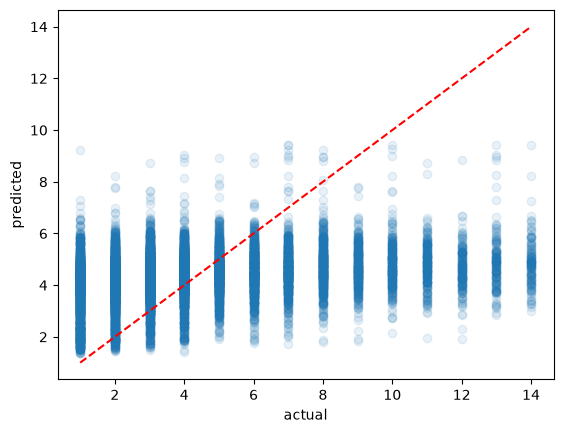

In [ ]:
# Predicted vs actual graph
y_pred = best_model.predict(X_test)
plt.scatter(y_test, y_pred, alpha=0.1)
plt.plot([1, 14], [1, 14], "r--")
plt.xlabel("actual"); plt.ylabel("predicted"); plt.show()

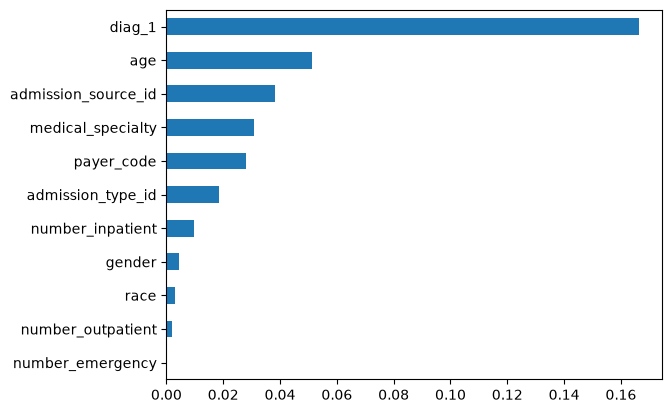

In [ ]:
# Feature importance based on permutation importance.
r = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42,
                           n_jobs=-1, scoring="neg_mean_absolute_error")
pd.Series(r.importances_mean, index=X_test.columns).sort_values().plot.barh()
plt.show()